# 1. 문제 정의
- 버섯 데이터를 활용하여 독버섯 데이터를 분류하기(의사결정나무 활용)

# 2. 데이터 수집
- 'mushroom.csv' 파일 불러오기

In [1]:
# 라이브러리 불러오기
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

In [2]:
# 데이터 불러오기(변수명 : data)
data = pd.read_csv('data/mushroom.csv')

# 3. 전처리 & 4. EDA
- 정보확인, 기술통계
- 인코딩

## (1) 정보, 기술 통계 확인

In [3]:
# 데이터의 정보 확인
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   poisonous                 8124 non-null   object
 1   cap-shape                 8124 non-null   object
 2   cap-surface               8124 non-null   object
 3   cap-color                 8124 non-null   object
 4   bruises                   8124 non-null   object
 5   odor                      8124 non-null   object
 6   gill-attachment           8124 non-null   object
 7   gill-spacing              8124 non-null   object
 8   gill-size                 8124 non-null   object
 9   gill-color                8124 non-null   object
 10  stalk-shape               8124 non-null   object
 11  stalk-root                8124 non-null   object
 12  stalk-surface-above-ring  8124 non-null   object
 13  stalk-surface-below-ring  8124 non-null   object
 14  stalk-color-above-ring  

In [4]:
# 데이터 기술 통계
data.describe(include = 'object')

,poisonous,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
count,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,...,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124
unique,2,6,4,10,2,9,2,2,2,12,...,4,9,9,1,4,3,5,9,6,7
top,e,x,y,n,f,n,f,c,b,b,...,s,w,w,p,w,o,p,w,v,d
freq,4208,3656,3244,2284,4748,3528,7914,6812,5612,1728,...,4936,4464,4384,8124,7924,7488,3968,2388,4040,3148


## (2) 전처리(인코딩)

- 전처리 전 문제/정답 데이터 분리
- 문제 데이터 X (특성, 속성, 피처, 독립변수): poisonous를 제외한 다른 모든 컬럼
- 정답 데이터 y (정답, 라벨, 레이블, 타겟, 종속변수) : poisonous

In [5]:
# 문제(X), 정답(y) 데이터 분리
x = data.iloc[:, 1:]
y = data['poisonous']

In [6]:
# X, y 확인
#x
#y

#data['poisonous'].unique()

- 인코딩(문자형 데이터 -> 수치형)
- 레이블인코딩(map(딕셔너리))
- 원핫인코딩(pd.get_dummies())

In [7]:
# 데이터에 우선순위 있는지 판단 후 인코딩 방법 선택
data = pd.get_dummies(data, dtype='int')
#data_po = data['poisonous'] = data['poisonous'].map({'p' : 0, 'e' : 1})

y = data['poisonous_p']
x = data.drop(columns=['poisonous_e', 'poisonous_p'])

## (3) train, test 데이터 분리

In [8]:
# 도구 불러오기
from sklearn.model_selection import train_test_split

In [9]:
# 분리비율 7:3 , 고정규칙 1, 클래스 비율 동일
x_train, x_test, y_train, y_test = train_test_split(
    x,y, #원본데이터(문제, 정답)
    test_size = 0.3, # 나누고 싶은 테스트 데이터의 비율
    random_state = 1, # 랜덤 데이터의 규칙을 고정
    stratify = y # 결과값이 범주형(분류모델)일 때, 훈련/테스트 클래스 비율 동일
)

In [10]:
# 분리 후, 데이터의 크기(형태) 확인
print('훈련 : ', x_train.shape, y_train.shape)
print('테스트 : ', x_test.shape, y_test.shape)

훈련 :  (5686, 117) (5686,)
테스트 :  (2438, 117) (2438,)


# 5. 모델 선택
- 모델객체 생성

In [11]:
# 모델 불러오기
from sklearn.tree import DecisionTreeClassifier

In [12]:
# 모델 객체 생성(하이퍼 파라미터 자율적으로 선택)(모델명 : tree)
tree = DecisionTreeClassifier()

# 6. 모델 학습

In [13]:
# 모델 학습
tree.fit(x_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


# 7. 모델 평가

In [14]:
# 모델 평가
print('훈련 : ', tree.score(x_train, y_train))
print('테스트 : ',tree.score(x_test, y_test))

훈련 :  1.0
테스트 :  1.0


In [15]:
# 교차 검증
from sklearn.model_selection import cross_val_score
cv = cross_val_score(tree, x_train, y_train, cv = 5)

# 추가. 트리 모델 시각화 및 특성 중요도 확인

In [16]:
# plot_tree 도구 불러오기
from sklearn.tree import plot_tree

In [17]:
# 한글 설정(rc : run control, 기본값 변경)
plt.rc('font', family='Malgun Gothic')
plt.rc('axes', unicode_minus = False) 

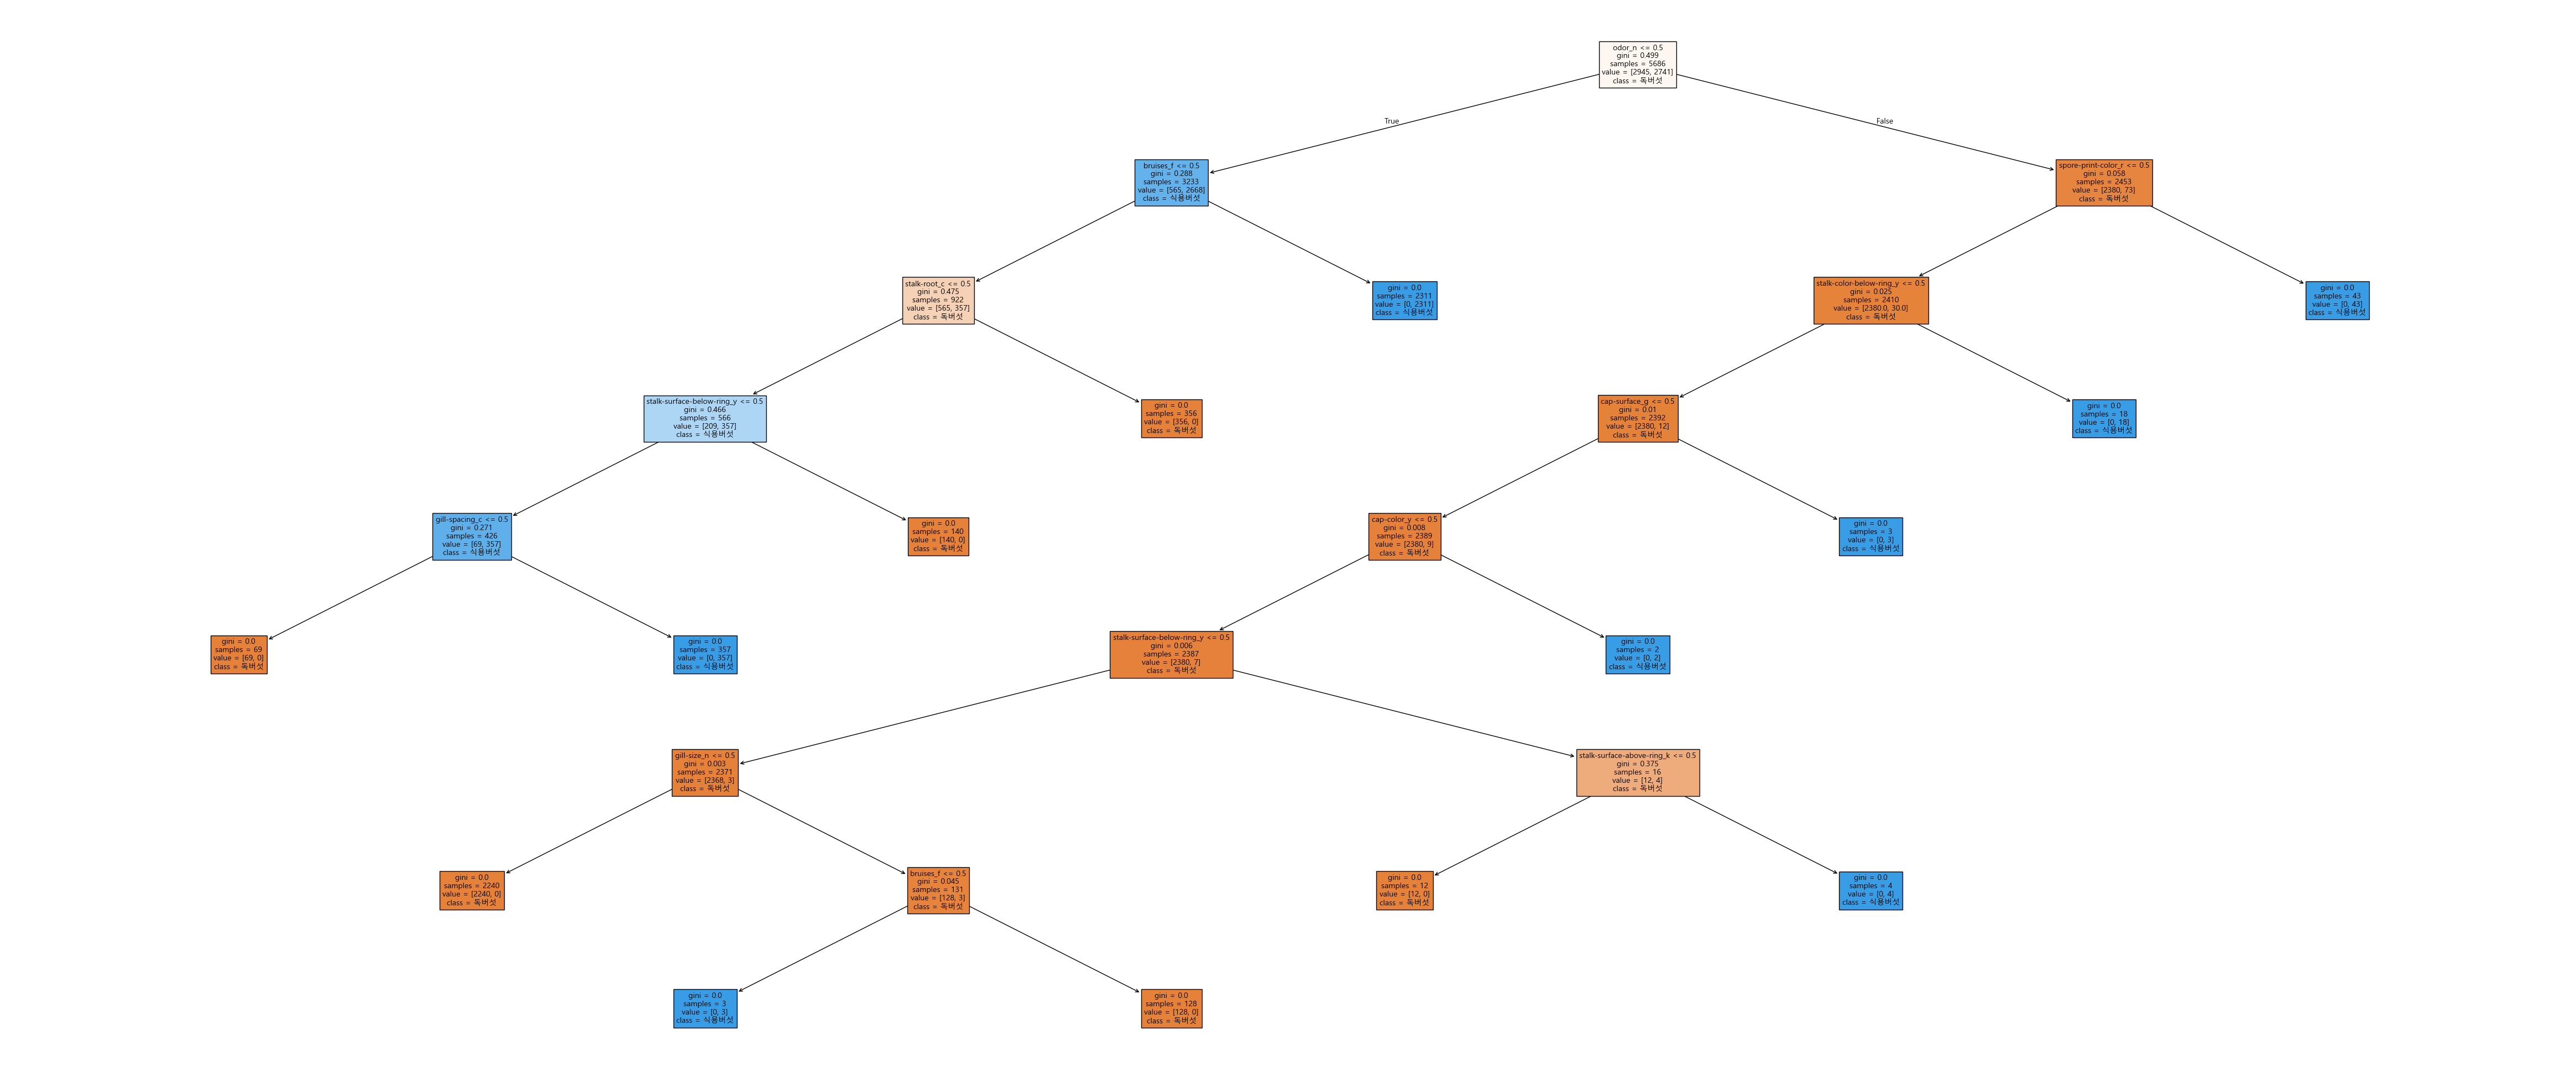

In [18]:
# 데이터 시각화
# 도화지 만들
plt.figure(figsize=(60,25))
# 트리 그리기
plot_tree(tree, feature_names = x_train.columns, 
                                class_names = ['독버섯', '식용버섯'], filled = True, fontsize=10)
# 시각화 및 초기화
plt.savefig('./data/poisonous.png', dpi = 300, bbox_inches='tight')
plt.show()

In [19]:
# 특성 중요도 확인
fi = tree.feature_importances_

# 결론

In [20]:
# 분석 및 모델 평가 결과와 특성 중요도 등 정리해보세요!
